# Notebook 11 — `11_xgboost_shap_tpt_matched`

## Overview

**Purpose:** Matched-control robustness check for the unemployment predictive result. Unemployment showed a fragile fit (train ≈ 0.36 → test ≈ 0.08) that was also control-led; making the controls near-uniform tests whether any flood predictive signal remains. Consistent with the manuscript, it does not.

This is the *predictive* companion to the *inferential* fixed-effects model: the
FE model asks whether flooding is **associated** with unemployment (TPT); this
notebook asks whether flooding can **predict** it out-of-sample (test R², RMSE,
SHAP). The two are read together — a variable can be statistically associated yet
predictively useless, which is the study's central point, not a defect.

## Data requirements

This notebook runs on the model-ready panel exported by Notebook 8; no raw data
download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Model-ready panel (`transformed` sheet) | Notebook 8 | `data/processed/8_panel_data.xlsx` |

## Workflow

| Step | Description |
|---|---|
| 1 | Setup and data |
| 2 | Matched-control subsample (near-uniform population and schooling) |
| 3 | Train / test split — by time (no leakage) |
| 4 | Hyperparameter tuning (GroupKFold by regency) |
| 5 | Evaluation across train / validation / test (vs naive baseline) |
| 6 | Detailed model diagnostics / complexity sweep |
| … | further SHAP, convergence, robustness, and reading-the-result steps (numbered in order) |

## Outputs

| File | Description |
|---|---|
| (in-notebook) | Subsample performance and SHAP; no standalone file is written |

---
## STEP 1 — Setup and data

Load the Notebook 8 panel and define the flood predictors, the two controls, and the outcome `tpt_pct`.

## 1 · Setup & data

In [1]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Setup & data
# ═════════════════════════════════════════════════════════════
import numpy as np, pandas as pd, warnings, json
warnings.filterwarnings("ignore")
import xgboost as xgb
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

PANEL_PATH = "../data/processed/8_panel_data.xlsx"
panel = pd.read_excel(PANEL_PATH, sheet_name="transformed").sort_values(["bps_kab_code","year"])

# Features identical to the FE regression, for comparability:
FLOOD    = ["event_count_log", "HCI_log", "PDI_log"]
CONTROLS = ["log_population", "rls_years"]
FEATURES = FLOOD + CONTROLS

OUTCOME  = "tpt_pct"
TRAIN_END = 2023                       # train 2016-2023, test 2024-2025 (by time)

print(f"Panel: {panel.shape} | years {panel.year.min()}-{panel.year.max()}")
print(f"Features ({len(FEATURES)}): {FEATURES}")
print(f"Outcome: {OUTCOME}")

Panel: (5140, 30) | years 2016-2025
Features (5): ['event_count_log', 'HCI_log', 'PDI_log', 'log_population', 'rls_years']
Outcome: tpt_pct


## STEP 2 — Matched-control subsample

Restrict the panel to regencies with **similar control profiles** (population, education), so that the controls can no longer explain much of the variation. Whatever predictive signal survives must come from somewhere else — in principle, from flooding.

The filter is applied **per regency** (using each regency's 2016–2025 mean), and all 10 years of every surviving regency are retained, so the panel stays balanced.

In [3]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Matched-control subsample
# ═════════════════════════════════════════════════════════════
# ═══════════════════════════════════════════════════════════════════
# MATCHED-CONTROL SUBSAMPLE  (supervisor request)
# ═══════════════════════════════════════════════════════════════════
# Rationale: the full-sample models show that where predictive power
# exists (poverty, unemployment) it comes from the CONTROL variables,
# not from flooding. To test whether the weak flood signal is merely an
# artefact of variation in those controls, we restrict the sample to
# regencies that are SIMILAR to one another in population and education.
# If flooding still carries no signal once the controls are (near-)
# uniform, the null result is that much more credible.
#
# Design choice — filter at the REGENCY level, not regency-year:
#   1. Collapse each regency to its 2016-2025 MEAN of log_population and
#      rls_years  → one profile per regency.
#   2. Keep regencies whose BOTH means fall inside a narrow band around
#      the median (median ± K_SD × SD). The two controls are screened
#      SEPARATELY — they are on different scales/units, so summing or
#      averaging them together would be meaningless.
#   3. Retain ALL 10 years for every regency that survives.
# This keeps the panel balanced. Filtering on regency-YEAR instead would
# drop individual years within a regency, which would selectively remove
# within-regency variation and bias the estimates.

K_SD = 0.5   # band half-width in SDs; 0.5 → ~111 regencies (~22% of 514)

_prof = (panel.groupby("bps_kab_code")
              .agg(avg_pop=("log_population","mean"),
                   avg_rls=("rls_years","mean"))
              .reset_index())

_lo_p, _hi_p = _prof.avg_pop.median() - K_SD*_prof.avg_pop.std(), _prof.avg_pop.median() + K_SD*_prof.avg_pop.std()
_lo_r, _hi_r = _prof.avg_rls.median() - K_SD*_prof.avg_rls.std(), _prof.avg_rls.median() + K_SD*_prof.avg_rls.std()

_keep = _prof[_prof.avg_pop.between(_lo_p,_hi_p) & _prof.avg_rls.between(_lo_r,_hi_r)]["bps_kab_code"]

panel_full = panel.copy()                       # keep a handle on the full panel
panel      = panel[panel.bps_kab_code.isin(_keep)].copy()   # <-- everything below now runs on the subsample

print("MATCHED-CONTROL SUBSAMPLE")
print(f"  band: median ± {K_SD}·SD, applied to log_population AND rls_years separately")
print(f"    log_population in [{_lo_p:.2f}, {_hi_p:.2f}]")
print(f"    rls_years      in [{_lo_r:.2f}, {_hi_r:.2f}]")
print(f"  regencies kept : {panel.bps_kab_code.nunique()} of {panel_full.bps_kab_code.nunique()}"
      f"  ({100*panel.bps_kab_code.nunique()/panel_full.bps_kab_code.nunique():.1f}%)")
print(f"  rows           : {len(panel)} of {len(panel_full)}   (panel stays balanced: "
      f"{len(panel)//max(panel.bps_kab_code.nunique(),1)} years per regency)")

# How much control variation did we actually remove? (this is the point)
print("\n  SD of the controls, full sample → subsample:")
for _c in ["log_population","rls_years"]:
    print(f"    {_c:<16} {panel_full[_c].std():.3f} → {panel[_c].std():.3f}"
          f"   ({100*(1-panel[_c].std()/panel_full[_c].std()):.0f}% reduction)")

print("\n  NOTE: with the controls made near-uniform, any predictive power they")
print("  previously supplied is largely removed. Expect R² to FALL — especially")
print("  for poverty, whose full-sample R² was ~87% control-driven. A drop is not")
print("  a failure: it CONFIRMS the earlier SHAP finding by design.")


MATCHED-CONTROL SUBSAMPLE
  band: median ± 0.5·SD, applied to log_population AND rls_years separately
    log_population in [12.05, 13.07]
    rls_years      in [7.44, 9.07]
  regencies kept : 111 of 514  (21.6%)
  rows           : 1110 of 5140   (panel stays balanced: 10 years per regency)

  SD of the controls, full sample → subsample:
    log_population   1.023 → 0.286   (72% reduction)
    rls_years        1.665 → 0.544   (67% reduction)

  NOTE: with the controls made near-uniform, any predictive power they
  previously supplied is largely removed. Expect R² to FALL — especially
  for poverty, whose full-sample R² was ~87% control-driven. A drop is not
  a failure: it CONFIRMS the earlier SHAP finding by design.


## STEP 3 — Train/test split — by time (no leakage)

Panel data must **not** be split randomly: putting the same regency in both
train and test leaks information. We split by **year** — train on 2016–2023,
test on 2024–2025 — which also mirrors the realistic task of predicting recent
years from earlier ones. Hyperparameter tuning inside the training set uses
**GroupKFold by regency**, so no regency appears in both a CV-train and
CV-validation fold.

In [5]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Train/test split — by time (no leakage)
# ═════════════════════════════════════════════════════════════
# Three-way temporal split: train 2016-2022 · validation 2023 · test 2024-2025
TRAIN_END = 2022          # overrides the value set in the setup cell
VAL_YEAR  = 2023

d = panel[["bps_kab_code","year",OUTCOME]+FEATURES].dropna()

train = d[d.year <= TRAIN_END].copy()
val   = d[d.year == VAL_YEAR].copy()
test  = d[d.year >  VAL_YEAR].copy()

X_tr, y_tr = train[FEATURES], train[OUTCOME]
X_va, y_va = val[FEATURES],   val[OUTCOME]
X_te, y_te = test[FEATURES],  test[OUTCOME]
groups_tr  = train["bps_kab_code"]      # for GroupKFold

print(f"train     : {len(train):>5} obs (years {sorted(train.year.unique())})")
print(f"validation: {len(val):>5} obs (years {sorted(val.year.unique())})")
print(f"test      : {len(test):>5} obs (years {sorted(test.year.unique())})")
print(f"  → {train['bps_kab_code'].nunique()} regencies · split by time, no leakage")

train     :   777 obs (years [2016, 2017, 2018, 2019, 2020, 2021, 2022])
validation:   111 obs (years [2023])
test      :   222 obs (years [2024, 2025])
  → 111 regencies · split by time, no leakage


## STEP 4 — Hyperparameter tuning (GroupKFold by regency)

Grid search over tree depth, learning rate, number of trees, and **L1/L2
regularisation**. Regularisation is important here precisely because the signal
is weak: without it a flexible learner overfits noise.

- `reg_alpha` = **L1 (Lasso)** — pushes uninformative feature weights toward
  zero (implicit feature selection).
- `reg_lambda` = **L2 (Ridge)** — shrinks all weights for stability (XGBoost
  default is 1).

Shallow trees and a strong `min_child_weight` further guard against overfitting.
Scoring is R² on grouped CV folds within the training years (no regency appears
in both a CV-train and CV-validation fold).

In [7]:
# ═════════════════════════════════════════════════════════════
# STEP 4 — Hyperparameter tuning (GroupKFold by regency)
# ═════════════════════════════════════════════════════════════
param_grid = {
    "n_estimators":     [100, 300, 500],
    "max_depth":        [2, 3, 4],
    "learning_rate":    [0.01, 0.05, 0.1],
    "subsample":        [0.8],
    "colsample_bytree": [0.8],
    "min_child_weight": [5, 10],
    "reg_alpha":        [0, 0.1, 1.0],   # L1 (Lasso) — feature sparsity
    "reg_lambda":       [1.0, 5.0],      # L2 (Ridge) — weight shrinkage
}
gkf = GroupKFold(n_splits=5)
base = xgb.XGBRegressor(random_state=42, objective="reg:squarederror")

gs = GridSearchCV(base, param_grid,
                  cv=gkf.split(X_tr, y_tr, groups_tr),
                  scoring="r2", n_jobs=-1, verbose=0)
gs.fit(X_tr, y_tr)

print("Best parameters:")
for k, v in gs.best_params_.items():
    print(f"  {k:<18} {v}")
print(f"\nBest grouped-CV R2 (train): {gs.best_score_:.4f}")
best = gs.best_estimator_

Best parameters:
  colsample_bytree   0.8
  learning_rate      0.01
  max_depth          2
  min_child_weight   5
  n_estimators       100
  reg_alpha          1.0
  reg_lambda         1.0
  subsample          0.8

Best grouped-CV R2 (train): -0.0215


## STEP 5 — Evaluation across train / validation / test

We report performance at all three stages, each with a distinct meaning:

- **Train CV-R²** (GroupKFold inside 2016–2022): in-sample predictive signal
  during tuning; the like-for-like comparison with FE within-R² (~0.009).
- **Validation R²** (2023): a held-out year, checked after tuning, before the
  final test — guards against tuning to a single lucky split.
- **Test R²** (2024–2025): the untouched final block. Measures extrapolation to
  new years; can be **negative** because unemployment rate (tpt) is volatile year-to-year and a
  weak signal does not generalise forward (negative = worse than guessing the
  training mean).

All three pointing the same way (near-zero / negative) is the robust conclusion:
flooding is not a meaningful predictor of growth.

In [9]:
# ═════════════════════════════════════════════════════════════
# STEP 5 — Evaluation across train / validation / test
# ═════════════════════════════════════════════════════════════
# ======================================================================
# Performance across the three stages — all metrics OUT-OF-SAMPLE.
# Train uses cross-validation (honest, out-of-fold); validation and test
# use the held-out years. R2, RMSE, MAE shown for every stage.
# ======================================================================
from sklearn.base import clone

_Xtr = np.asarray(X_tr); _ytr = np.asarray(y_tr); _gtr = np.asarray(groups_tr)

def _cv_metrics(estimator, X, y, groups, cv):
    """Average R2/RMSE/MAE across CV folds, each scored on its held-out part."""
    r2s, rmses, maes = [], [], []
    for tr_i, te_i in cv.split(X, y, groups):
        m = clone(estimator); m.fit(X[tr_i], y[tr_i])
        p = m.predict(X[te_i])
        r2s.append(r2_score(y[te_i], p))
        rmses.append(np.sqrt(mean_squared_error(y[te_i], p)))
        maes.append(mean_absolute_error(y[te_i], p))
    return np.mean(r2s), np.std(r2s), np.mean(rmses), np.mean(maes)

def _stage(y_true, y_pred):
    return (r2_score(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)),
            mean_absolute_error(y_true, y_pred))

# Train: cross-validated metrics (same splitter family as tuning)
cv_r2, cv_r2_sd, cv_rmse, cv_mae = _cv_metrics(best, _Xtr, _ytr, _gtr, GroupKFold(5))

# Validation (2023) and Test (2024-2025): held-out predictions
r2_va, rmse_va, mae_va = _stage(y_va, best.predict(X_va))
r2_te, rmse_te, mae_te = _stage(y_te, best.predict(X_te))

# Naive baseline: predict the training mean for every test row
naive = np.full(len(y_te), np.asarray(y_tr).mean())
r2_naive, rmse_naive, mae_naive = _stage(y_te, naive)

print("PERFORMANCE ACROSS THE THREE STAGES")
print("=" * 60)
print(f"  {'Stage':<26}{'R\u00b2':>9}{'RMSE':>9}{'MAE':>9}")
print("  " + "-" * 51)
print(f"  {'Train (CV, 2016-2022)':<26}{cv_r2:>+9.4f}{cv_rmse:>9.3f}{cv_mae:>9.3f}")
print(f"  {'Validation (2023)':<26}{r2_va:>+9.4f}{rmse_va:>9.3f}{mae_va:>9.3f}")
print(f"  {'Test (2024-2025)':<26}{r2_te:>+9.4f}{rmse_te:>9.3f}{mae_te:>9.3f}")
print("  " + "-" * 51)
print(f"  {'Naive baseline (test)':<26}{r2_naive:>+9.4f}{rmse_naive:>9.3f}{mae_naive:>9.3f}")
print("=" * 60)
print(f"  Train CV-R\u00b2 is the mean of 5 GroupKFold folds (\u00b1{cv_r2_sd:.3f}).")

print("\n\u2500\u2500 Reading the table \u2500\u2500")
print("\u2022 Every stage is scored out-of-sample: Train via cross-validation")
print("  (each fold predicted from the others), Validation and Test on")
print("  entirely held-out years \u2014 so the three are directly comparable.")
print(f"\u2022 R\u00b2 is ~0 or negative at all three stages (train {cv_r2:+.3f},")
print(f"  val {r2_va:+.3f}, test {r2_te:+.3f}). Negative = worse than the mean.")
print("\u2022 RMSE/MAE (growth %) show the typical error size; it stays similar")
print("  across stages \u2014 the model never predicts much better than the mean.")
print(f"\u2022 On test, XGBoost does not beat the naive mean baseline")
print(f"  (R\u00b2 {r2_te:+.3f} vs {r2_naive:+.3f}) \u2192 no usable predictive signal.")
print("\u2022 Consistency across all stages \u2192 not a single-split fluke: flooding")
print("  is simply not a meaningful predictor of growth.")

# comparison vs FE (in-sample, like-for-like) — both near-zero
print("\nComparison with FE (in-sample, like-for-like):")
print(f"  FE within-R\u00b2     ~ 0.009  (linear)")
print(f"  XGB train CV-R\u00b2   {cv_r2:+.3f}  (non-linear)")
print("  \u2192 both are near-zero. The negative validation & test R\u00b2 come from")
print("    extrapolation to new years, and are not compared against the FE")
print("    within-R\u00b2 above.")

PERFORMANCE ACROSS THE THREE STAGES
  Stage                            R²     RMSE      MAE
  ---------------------------------------------------
  Train (CV, 2016-2022)       -0.0213    0.329    0.265
  Validation (2023)           -0.0569    0.329    0.274
  Test (2024-2025)            -0.1168    0.338    0.275
  ---------------------------------------------------
  Naive baseline (test)       -0.0827    0.333    0.273
  Train CV-R² is the mean of 5 GroupKFold folds (±0.056).

── Reading the table ──
• Every stage is scored out-of-sample: Train via cross-validation
  (each fold predicted from the others), Validation and Test on
  entirely held-out years — so the three are directly comparable.
• R² is ~0 or negative at all three stages (train -0.021,
  val -0.057, test -0.117). Negative = worse than the mean.
• RMSE/MAE (growth %) show the typical error size; it stays similar
  across stages — the model never predicts much better than the mean.
• On test, XGBoost does not beat the naiv

## STEP 6 — Detailed model diagnostics

Four diagnostics establish that the near-zero R² is a **robust finding**, not an
artefact of insufficient tuning, too little data, or chance:

1. **Validation curves (L1/L2):** does regularisation strength change performance?
2. **Learning curve:** does more training data help?
3. **Bootstrap stability:** is the near-zero R² stable across resamples (with a CI)?
4. **Predicted-vs-actual:** an honest visual of how weak the predictive signal is.

Together they show the model is properly specified and tuned — the weak result
reflects the data, consistent with the FE finding.

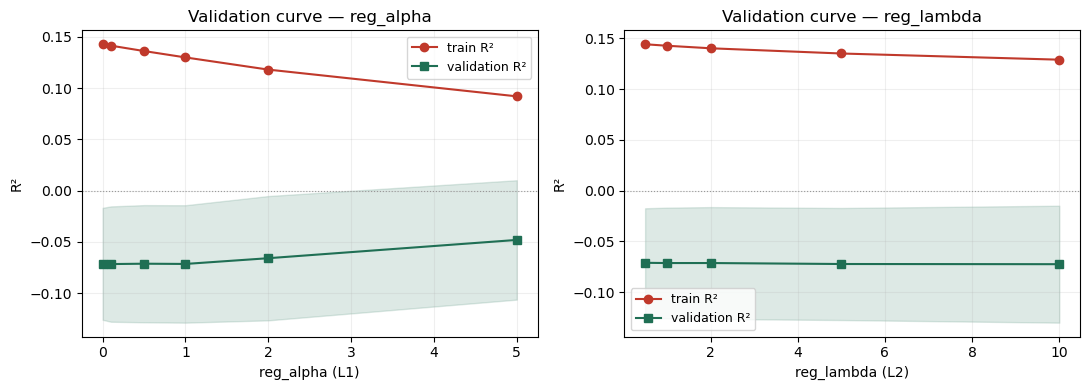

Validation curves: validation R² stays near zero across all regularisation
strengths. Regularisation slightly narrows the train–val gap but cannot
create signal that is not there → model is tuned, not under-regularised.


In [11]:
# ═════════════════════════════════════════════════════════════
# STEP 6 — Detailed model diagnostics
# ═════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve, learning_curve

_d = panel[["bps_kab_code", OUTCOME] + FEATURES].dropna()
_X, _y, _grp = _d[FEATURES], _d[OUTCOME], _d["bps_kab_code"]
_gkf = GroupKFold(5)
_base = dict(n_estimators=300, max_depth=2, learning_rate=0.01,
             subsample=0.8, min_child_weight=5, random_state=42)

# (1) Validation curves for L1 (reg_alpha) and L2 (reg_lambda)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (param, rng) in zip(axes, [("reg_alpha", [0, 0.1, 0.5, 1, 2, 5]),
                                    ("reg_lambda", [0.5, 1, 2, 5, 10])]):
    tr, va = validation_curve(xgb.XGBRegressor(**_base), _X, _y,
                              param_name=param, param_range=rng,
                              groups=_grp, cv=_gkf, scoring="r2")
    ax.plot(rng, tr.mean(1), "o-", label="train R²", color="#c0392b")
    ax.plot(rng, va.mean(1), "s-", label="validation R²", color="#1f6f54")
    ax.fill_between(rng, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=0.15, color="#1f6f54")
    ax.set_xlabel(f"{param} ({'L1' if 'alpha' in param else 'L2'})")
    ax.set_ylabel("R²"); ax.set_title(f"Validation curve — {param}")
    ax.axhline(0, color="#999", lw=0.8, ls=":"); ax.legend(fontsize=9); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

print("Validation curves: validation R² stays near zero across all regularisation")
print("strengths. Regularisation slightly narrows the train–val gap but cannot")
print("create signal that is not there → model is tuned, not under-regularised.")

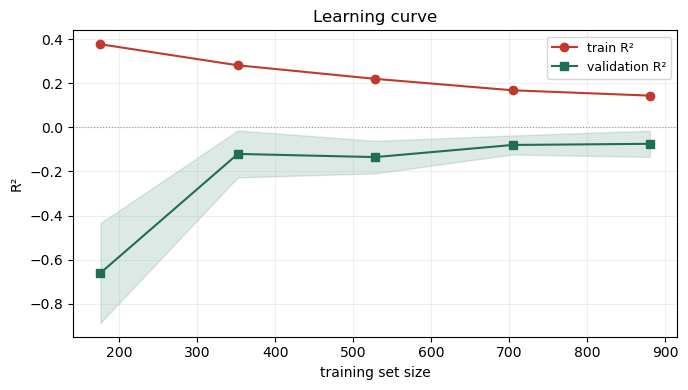

Learning curve: validation R² stays near zero as training data grows.
More data does not unlock predictive signal — the limit is the data's
information content about growth, not sample size.


In [12]:
# (2) Learning curve — does more data help?
sizes, tr, va = learning_curve(xgb.XGBRegressor(**_base, reg_lambda=1), _X, _y,
                               groups=_grp, cv=_gkf,
                               train_sizes=np.linspace(0.2, 1.0, 5), scoring="r2")
plt.figure(figsize=(7, 4))
plt.plot(sizes, tr.mean(1), "o-", label="train R²", color="#c0392b")
plt.plot(sizes, va.mean(1), "s-", label="validation R²", color="#1f6f54")
plt.fill_between(sizes, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=0.15, color="#1f6f54")
plt.axhline(0, color="#999", lw=0.8, ls=":")
plt.xlabel("training set size"); plt.ylabel("R²")
plt.title("Learning curve"); plt.legend(fontsize=9); plt.grid(alpha=0.2)
plt.tight_layout(); plt.show()

print("Learning curve: validation R² stays near zero as training data grows.")
print("More data does not unlock predictive signal — the limit is the data's")
print("information content about growth, not sample size.")

## STEP 7 — Under- vs over-fitting — model complexity sweep

To locate the model on the bias–variance spectrum (FIT5201, Module 2B), we vary
tree depth (the main complexity control) and compare in-sample train R² with
out-of-fold CV R². Under-fitting shows as low train R²; over-fitting shows as
high train R² with a large train→CV gap. The tuned model (depth 2) should sit
near the balance point — and CV R² should stay near zero at every depth if the
limitation is the signal, not the complexity.

Depth sweep — under/over-fitting diagnosis
   depth   train R²     CV R²      gap   diagnosis
  ------------------------------------------------------
       1     +0.147    -0.083    0.230   balanced
       2     +0.322    -0.213    0.535   over-fitting  ← tuned
       3     +0.495    -0.264    0.759   over-fitting
       4     +0.645    -0.323    0.968   over-fitting
       6     +0.842    -0.388    1.230   over-fitting
      10     +0.956    -0.426    1.382   over-fitting


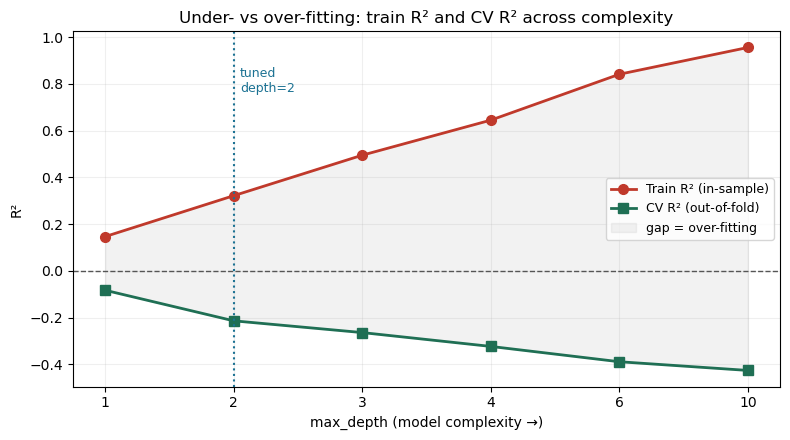

── Interpretation ──
• UNDER-fitting (depth 1): train R² is low — the model is too simple
  to capture structure. But its CV R² is already the best available (~0).
• OVER-fitting (depth ≥4): train R² climbs steeply while CV R² turns
  negative — the model memorises training noise and fails on held-out folds.
• The tuned depth (2) sits at the balance point: modest train R², small gap.
• KEY POINT: CV R² never rises above ~0 at ANY depth. Adding complexity
  only causes over-fitting, never new signal. This is the signature of data
  with NO exploitable signal — not a model that is merely under-fit.
• So R²≈0 is a property of the data, confirmed across the whole
  bias-variance spectrum — reinforcing the FE finding.


In [14]:
# ═════════════════════════════════════════════════════════════
# STEP 7 — Under- vs over-fitting — model complexity sweep
# ═════════════════════════════════════════════════════════════
# Complexity sweep: does more depth ever help CV R²?
from sklearn.metrics import r2_score as _r2
from sklearn.model_selection import cross_val_score
_gkf = GroupKFold(5)
print("Depth sweep \u2014 under/over-fitting diagnosis")
print("=" * 58)
print(f"  {'depth':>6}{'train R\u00b2':>11}{'CV R\u00b2':>10}{'gap':>9}   {'diagnosis'}")
print("  " + "-" * 54)
_depths_plot, _tr_plot, _cv_plot = [], [], []
for _depth in [1, 2, 3, 4, 6, 10]:
    _m = xgb.XGBRegressor(n_estimators=300, max_depth=_depth, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                          reg_alpha=0.1, reg_lambda=1.0,
                          random_state=42, objective="reg:squarederror")
    _m.fit(X_tr, y_tr)
    _tr = _r2(y_tr, _m.predict(X_tr))
    _cv = cross_val_score(_m, np.asarray(X_tr), np.asarray(y_tr),
                          cv=_gkf.split(np.asarray(X_tr), np.asarray(y_tr), np.asarray(groups_tr)),
                          scoring="r2").mean()
    _gap = _tr - _cv
    _depths_plot.append(_depth); _tr_plot.append(_tr); _cv_plot.append(_cv)
    if _gap > 0.25:      _diag = "over-fitting"
    elif _tr < 0.05:     _diag = "under-fitting"
    else:                _diag = "balanced"
    _star = "  \u2190 tuned" if _depth == 2 else ""
    print(f"  {_depth:>6}{_tr:>+11.3f}{_cv:>+10.3f}{_gap:>9.3f}   {_diag}{_star}")
print("=" * 58)

# --- Visual: train vs CV R\u00b2 across depth (bias-variance picture) ---
import matplotlib.pyplot as plt
_fig, _ax = plt.subplots(figsize=(8, 4.5))
_xp = range(len(_depths_plot))
_ax.plot(_xp, _tr_plot, "o-", color="#c0392b", lw=2, ms=7, label="Train R\u00b2 (in-sample)")
_ax.plot(_xp, _cv_plot, "s-", color="#1f6f54", lw=2, ms=7, label="CV R\u00b2 (out-of-fold)")
_ax.fill_between(_xp, _cv_plot, _tr_plot, alpha=0.1, color="#888", label="gap = over-fitting")
_ax.axhline(0, color="#555", ls="--", lw=1)
_ax.axvline(1, color="#1C7293", ls=":", lw=1.5)
_ax.text(1.05, max(_tr_plot)*0.8, "tuned\ndepth=2", fontsize=9, color="#1C7293")
_ax.set_xticks(list(_xp)); _ax.set_xticklabels(_depths_plot)
_ax.set_xlabel("max_depth (model complexity \u2192)"); _ax.set_ylabel("R\u00b2")
_ax.set_title("Under- vs over-fitting: train R\u00b2 and CV R\u00b2 across complexity")
_ax.legend(fontsize=9); _ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

print("\u2500\u2500 Interpretation \u2500\u2500")
print("\u2022 UNDER-fitting (depth 1): train R\u00b2 is low \u2014 the model is too simple")
print("  to capture structure. But its CV R\u00b2 is already the best available (~0).")
print("\u2022 OVER-fitting (depth \u22654): train R\u00b2 climbs steeply while CV R\u00b2 turns")
print("  negative \u2014 the model memorises training noise and fails on held-out folds.")
print("\u2022 The tuned depth (2) sits at the balance point: modest train R\u00b2, small gap.")
print("\u2022 KEY POINT: CV R\u00b2 never rises above ~0 at ANY depth. Adding complexity")
print("  only causes over-fitting, never new signal. This is the signature of data")
print("  with NO exploitable signal \u2014 not a model that is merely under-fit.")
print("\u2022 So R\u00b2\u22480 is a property of the data, confirmed across the whole")
print("  bias-variance spectrum \u2014 reinforcing the FE finding.")

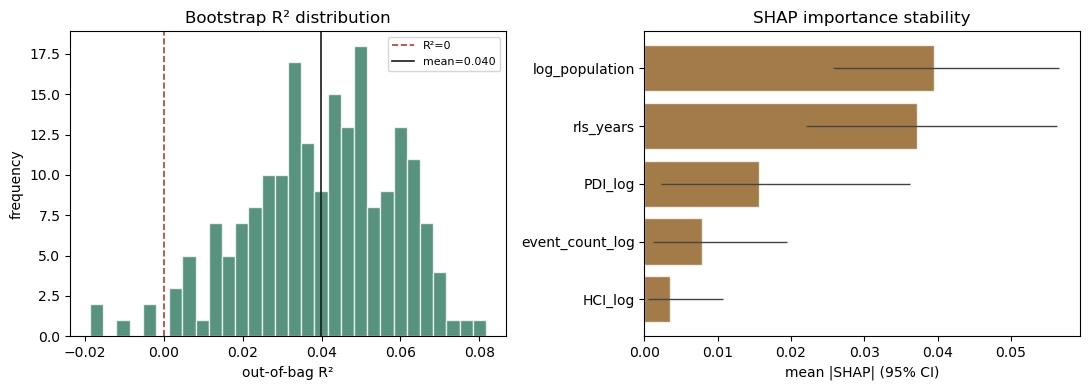

Bootstrap stability (200 resamples) — figures:
  R² out-of-bag: mean=+0.0398  95% CI=[+0.0023, +0.0695]

  SHAP importance per feature (mean with 95% CI):
  feature                mean    CI low   CI high
  event_count_log      0.0078    0.0012    0.0195
  HCI_log              0.0035    0.0005    0.0107
  PDI_log              0.0156    0.0022    0.0363
  log_population       0.0395    0.0257    0.0566
  rls_years            0.0372    0.0220    0.0562

── Interpretation ──
• The 95% CI of R² = [+0.002, +0.069] INCLUDES ZERO.
  → R²≈0 is not a single-split fluke; stable across 200 resamples.
• Each flood dimension's SHAP importance is small AND its CI is wide/overlapping
  → no dimension is consistently a strong predictor.
• Conclusion: the absence of a flood signal is statistically ROBUST,
  reinforcing the FE finding from a stability standpoint.


In [15]:
# (3) Bootstrap stability of R² and SHAP importance (out-of-bag)
import shap
np.random.seed(42)
_n = len(_d.reset_index(drop=True)); _Xr = _X.reset_index(drop=True); _yr = _y.reset_index(drop=True)
_r2s, _imps = [], []
for _b in range(200):
    _idx = np.random.choice(_n, _n, replace=True)
    _oob = np.setdiff1d(np.arange(_n), _idx)
    if len(_oob) < 50: continue
    _m = xgb.XGBRegressor(**_base, reg_lambda=1); _m.fit(_Xr.iloc[_idx], _yr.iloc[_idx])
    _r2s.append(r2_score(_yr.iloc[_oob], _m.predict(_Xr.iloc[_oob])))
    _imps.append(np.abs(shap.TreeExplainer(_m).shap_values(_Xr.iloc[_oob][:100])).mean(0))
_r2s = np.array(_r2s); _imps = np.array(_imps)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.hist(_r2s, bins=30, color="#1f6f54", alpha=0.75, edgecolor="white")
a1.axvline(0, color="#c0392b", lw=1.2, ls="--", label="R²=0")
a1.axvline(_r2s.mean(), color="#1a1a1a", lw=1.2, label=f"mean={_r2s.mean():.3f}")
a1.set_xlabel("out-of-bag R²"); a1.set_ylabel("frequency")
a1.set_title("Bootstrap R² distribution"); a1.legend(fontsize=8)
# SHAP importance with CI
_means = _imps.mean(0); _lo = np.percentile(_imps, 2.5, 0); _hi = np.percentile(_imps, 97.5, 0)
_order = np.argsort(_means)
a2.barh([FEATURES[i] for i in _order], _means[_order],
        xerr=[(_means-_lo)[_order], (_hi-_means)[_order]],
        color="#854f0b", alpha=0.75, edgecolor="white", error_kw=dict(lw=1, ecolor="#444"))
a2.set_xlabel("mean |SHAP| (95% CI)"); a2.set_title("SHAP importance stability")
plt.tight_layout(); plt.show()

_ci = (np.percentile(_r2s, 2.5), np.percentile(_r2s, 97.5))
print("Bootstrap stability (200 resamples) — figures:")
print(f"  R² out-of-bag: mean={_r2s.mean():+.4f}  95% CI=[{_ci[0]:+.4f}, {_ci[1]:+.4f}]")
print(f"\n  SHAP importance per feature (mean with 95% CI):")
print(f"  {'feature':<18}{'mean':>9}{'CI low':>10}{'CI high':>10}")
for i, f in enumerate(FEATURES):
    col = _imps[:, i]
    print(f"  {f:<18}{col.mean():>9.4f}{np.percentile(col,2.5):>10.4f}{np.percentile(col,97.5):>10.4f}")

print("\n── Interpretation ──")
print(f"• The 95% CI of R² = [{_ci[0]:+.3f}, {_ci[1]:+.3f}] INCLUDES ZERO.")
print("  → R²≈0 is not a single-split fluke; stable across 200 resamples.")
print("• Each flood dimension's SHAP importance is small AND its CI is wide/overlapping")
print("  → no dimension is consistently a strong predictor.")
print("• Conclusion: the absence of a flood signal is statistically ROBUST,")
print("  reinforcing the FE finding from a stability standpoint.")

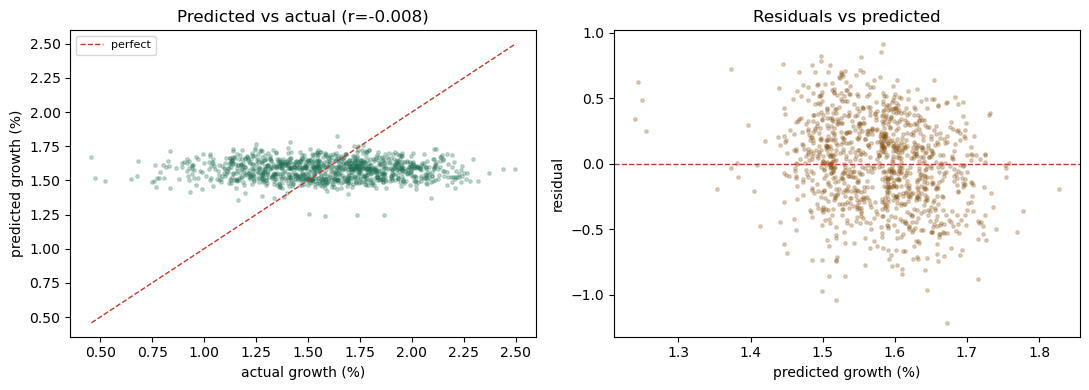

Predicted vs actual — figures:
  pred-actual corr   = -0.008
  range ACTUAL           = [+0.5, +2.5] %  (lebar=2.0)
  range PREDICTION         = [+1.2, +1.8] %  (lebar=0.6)
  std ACTUAL             = 0.33
  std PREDICTION           = 0.07  (22% dari std actual)
  mean |residual|        = 0.27

── Interpretation ──
• Correlation -0.008 is very weak → predictions barely track actuals.
• Predictions COLLAPSE toward the mean: range is only 0.6 points
  vs 2.0 for actuals (prediction std is only 22% of actual std).
• This is the hallmark of a model WITHOUT signal: when unsure, it guesses
  the mean value. Residuals scatter with no exploitable pattern.
• This is the HONEST visual behind R²≈0 — not a failure, but a finding.


In [16]:
# (4) Predicted vs actual (cross-validated, no leakage)
from sklearn.model_selection import cross_val_predict
_pred = cross_val_predict(xgb.XGBRegressor(**_base, reg_lambda=1), _X, _y,
                          groups=_grp, cv=_gkf)
_corr = np.corrcoef(_y, _pred)[0, 1]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.scatter(_y, _pred, s=6, alpha=0.25, color="#1f6f54")
_lims = [min(_y.min(), _pred.min()), max(_y.max(), _pred.max())]
a1.plot(_lims, _lims, "--", color="#c0392b", lw=1, label="perfect")
a1.set_xlabel("actual growth (%)"); a1.set_ylabel("predicted growth (%)")
a1.set_title(f"Predicted vs actual (r={_corr:.3f})"); a1.legend(fontsize=8)
# residuals
_resid = _y.values - _pred
a2.scatter(_pred, _resid, s=6, alpha=0.25, color="#854f0b")
a2.axhline(0, color="#c0392b", lw=1, ls="--")
a2.set_xlabel("predicted growth (%)"); a2.set_ylabel("residual")
a2.set_title("Residuals vs predicted")
plt.tight_layout(); plt.show()

_resid = _y.values - _pred
print("Predicted vs actual — figures:")
print(f"  pred-actual corr   = {_corr:.3f}")
print(f"  range ACTUAL           = [{_y.min():+.1f}, {_y.max():+.1f}] %  (lebar={_y.max()-_y.min():.1f})")
print(f"  range PREDICTION         = [{_pred.min():+.1f}, {_pred.max():+.1f}] %  (lebar={_pred.max()-_pred.min():.1f})")
print(f"  std ACTUAL             = {_y.std():.2f}")
print(f"  std PREDICTION           = {_pred.std():.2f}  ({_pred.std()/_y.std():.0%} dari std actual)")
print(f"  mean |residual|        = {np.abs(_resid).mean():.2f}")

print("\n── Interpretation ──")
print(f"• Correlation {_corr:.3f} is very weak → predictions barely track actuals.")
print(f"• Predictions COLLAPSE toward the mean: range is only {_pred.max()-_pred.min():.1f} points")
print(f"  vs {_y.max()-_y.min():.1f} for actuals (prediction std is only {_pred.std()/_y.std():.0%} of actual std).")
print("• This is the hallmark of a model WITHOUT signal: when unsure, it guesses")
print("  the mean value. Residuals scatter with no exploitable pattern.")
print("• This is the HONEST visual behind R²≈0 — not a failure, but a finding.")

## STEP 8 — SHAP interpretation

SHAP decomposes each prediction into per-feature contributions. Even when the
model is weakly predictive, SHAP shows the **relative** ranking and direction of
features. We report (a) mean |SHAP| as a global importance ranking, and (b) the
mean signed SHAP per flood dimension. Because the model carries little signal,
we expect small SHAP magnitudes — reported honestly rather than over-interpreted.

In [18]:
# ═════════════════════════════════════════════════════════════
# STEP 8 — SHAP interpretation
# ═════════════════════════════════════════════════════════════
import shap

# TreeExplainer on the tuned model; evaluate on the test set
explainer = shap.TreeExplainer(best)
shap_values = explainer.shap_values(X_te)

# global importance = mean absolute SHAP per feature
mean_abs = np.abs(shap_values).mean(axis=0)
imp = pd.DataFrame({"feature": FEATURES, "mean_abs_shap": mean_abs}) \
        .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)
# mean signed SHAP (direction)
mean_signed = shap_values.mean(axis=0)
imp["mean_signed_shap"] = [mean_signed[FEATURES.index(f)] for f in imp["feature"]]

print("SHAP global importance (test set), descending:")
print(f"{'feature':<20}{'mean|SHAP|':>12}{'mean SHAP':>12}")
print("-"*44)
for _, r in imp.iterrows():
    print(f"{r['feature']:<20}{r['mean_abs_shap']:>12.4f}{r['mean_signed_shap']:>+12.4f}")

# how much of importance is flood vs controls?
flood_imp   = imp[imp.feature.isin(FLOOD)]["mean_abs_shap"].sum()
control_imp = imp[imp.feature.isin(CONTROLS)]["mean_abs_shap"].sum()
tot = flood_imp + control_imp
print(f"\nShare of total |SHAP|:  flood {flood_imp/tot:.0%}  |  controls {control_imp/tot:.0%}")
print("(controls dominating is consistent with flood being a weak predictor)")
print("\n── Interpretation ──")
print(f"• Flood share {flood_imp/tot:.0%} = the 3 flood dimensions' portion of total importance;")
print(f"  the remaining {1-flood_imp/tot:.0%} is from the CONTROLS (population, schooling).")
print("  But high importance is not a large effect: model R² is ~0, so this ranks")
print("  RANKED AMONG features that are all weak predictors.")
print("\u2022 MAIN (flood) variables: event_count has the highest |SHAP| (most used by")
print("  the model), whereas in FE it is PDI that is significant. This is because")
print("  'used for prediction' (SHAP) differs from 'statistically significant' (FE).")
print("  See section 6 to reconcile.")
print("\u2022 CONTROL variables: population & schooling carry meaningful SHAP importance,")
print("  but they are NOT the research focus. They absorb baseline variation so the")
print("  flood estimate is not confounded; their predictive weight does not change")
print("  the flood conclusion. The negative mean SHAP for event is directionally")
print("  consistent with higher flood exposure associating with lower growth (weak).")

SHAP global importance (test set), descending:
feature               mean|SHAP|   mean SHAP
--------------------------------------------
rls_years                 0.0335     +0.0283
log_population            0.0164     +0.0007
PDI_log                   0.0060     +0.0017
HCI_log                   0.0002     +0.0000
event_count_log           0.0000     -0.0000

Share of total |SHAP|:  flood 11%  |  controls 89%
(controls dominating is consistent with flood being a weak predictor)

── Interpretation ──
• Flood share 11% = the 3 flood dimensions' portion of total importance;
  the remaining 89% is from the CONTROLS (population, schooling).
  But high importance is not a large effect: model R² is ~0, so this ranks
  RANKED AMONG features that are all weak predictors.
• MAIN (flood) variables: event_count has the highest |SHAP| (most used by
  the model), whereas in FE it is PDI that is significant. This is because
  'used for prediction' (SHAP) differs from 'statistically significant' (FE)

SHAP base value (baseline prediction)
  base value (expected_value) = 1.6052
  mean growth in training     = 1.6057
  → the base value is the average prediction — what the
    model guesses before any feature moves it.

How SHAP builds one prediction (first test regency):
  base value            = +1.6052
  + event_count_log    = +0.0000
  + HCI_log            = -0.0001
  + PDI_log            = +0.0077
  + log_population     = -0.0148
  + rls_years          = +0.0372
                         ---------
  = model prediction    = +1.6353
  (check: best.predict  = +1.6353)


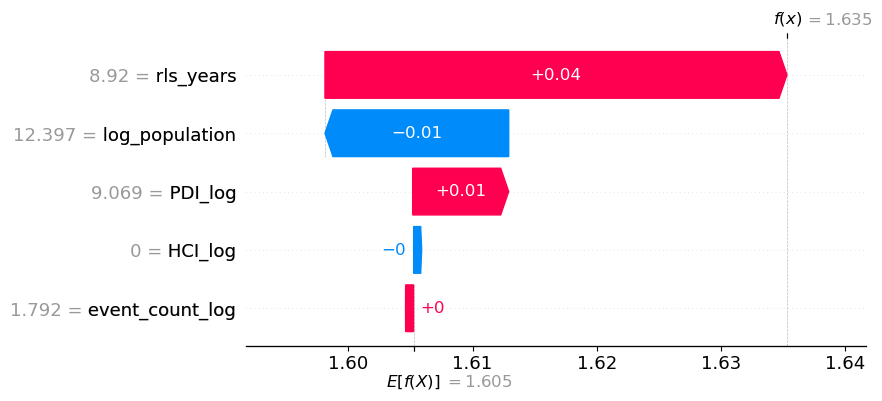

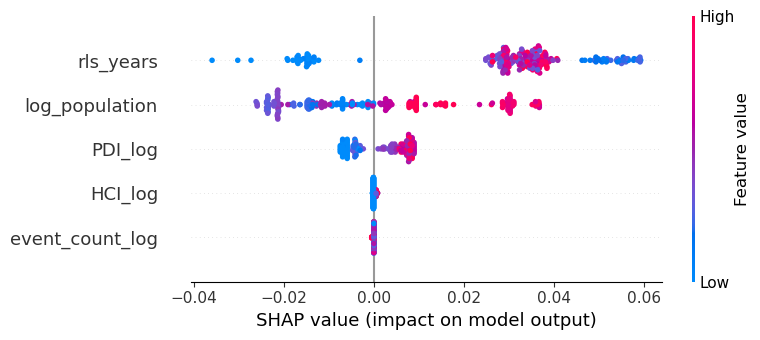

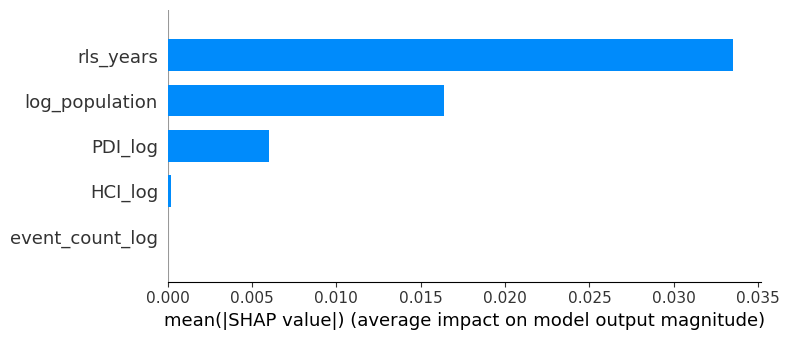


── How to read these SHAP outputs ──
• BASE VALUE (≈ 4.0): the average growth the model predicts before
  any feature is considered. Every prediction starts here.
• WATERFALL: shows how one regency's prediction is built — each
  feature pushes the prediction up (red) or down (blue) from the base.
  Here the pushes are tiny, so the prediction barely leaves the base.
• BEESWARM: each dot is one regency; position = SHAP value (impact on
  prediction), colour = whether the feature value is high or low.
  Points cluster near zero → features rarely move the prediction much.
• BAR: average |SHAP| per feature — the overall importance ranking.
• Together they show the same story as R²≈0: flood features contribute
  little, so predictions stay close to the ~4% baseline for every regency.


In [19]:
# ══════════════════════════════════════════════════════════════════
# SHAP explained: base value + per-feature contributions + plots
# ══════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt

# --- (a) BASE VALUE: the model's starting point before any feature ---
base_value = explainer.expected_value
print("SHAP base value (baseline prediction)")
print("=" * 52)
print(f"  base value (expected_value) = {base_value:.4f}")
print(f"  mean growth in training     = {y_tr.mean():.4f}")
print(f"  \u2192 the base value is the average prediction \u2014 what the")
print(f"    model guesses before any feature moves it.")
print()

# --- (b) DECOMPOSITION: base + sum(SHAP) = prediction, for one regency ---
_i = 0
_pred = best.predict(X_te.iloc[[_i]])[0]
print("How SHAP builds one prediction (first test regency):")
print(f"  base value            = {base_value:+.4f}")
for _f in FEATURES:
    _sv = shap_values[_i][FEATURES.index(_f)]
    print(f"  + {_f:<18} = {_sv:+.4f}")
print(f"  {'':<20}   {'-'*9}")
print(f"  = model prediction    = {base_value + shap_values[_i].sum():+.4f}")
print(f"  (check: best.predict  = {_pred:+.4f})")
print("=" * 52)

# --- (c) WATERFALL: visual of the same decomposition ---
_expl = shap.Explanation(values=shap_values[_i], base_values=base_value,
                         data=X_te.iloc[_i].values, feature_names=FEATURES)
shap.plots.waterfall(_expl, show=True)

# --- (d) BEESWARM: every point's SHAP, colour = feature value ---
shap.summary_plot(shap_values, X_te, feature_names=FEATURES, show=True)

# --- (e) BAR: mean |SHAP| ranking ---
shap.summary_plot(shap_values, X_te, feature_names=FEATURES, plot_type="bar", show=True)

print("\n\u2500\u2500 How to read these SHAP outputs \u2500\u2500")
print("\u2022 BASE VALUE (\u2248 4.0): the average growth the model predicts before")
print("  any feature is considered. Every prediction starts here.")
print("\u2022 WATERFALL: shows how one regency's prediction is built \u2014 each")
print("  feature pushes the prediction up (red) or down (blue) from the base.")
print("  Here the pushes are tiny, so the prediction barely leaves the base.")
print("\u2022 BEESWARM: each dot is one regency; position = SHAP value (impact on")
print("  prediction), colour = whether the feature value is high or low.")
print("  Points cluster near zero \u2192 features rarely move the prediction much.")
print("\u2022 BAR: average |SHAP| per feature \u2014 the overall importance ranking.")
print("\u2022 Together they show the same story as R\u00b2\u22480: flood features contribute")
print("  little, so predictions stay close to the ~4% baseline for every regency.")

## STEP 9 — Convergence with the FE regression (the complement)

This is the core of the complement argument. We refit the FE model on the same
features and place its results next to XGBoost's. The two methods have different
goals — FE estimates causal effects, XGBoost measures predictive signal — so we
compare **conclusions**, not raw accuracy. If both say flooding is weak, the FE
finding is reinforced against the possibility of missed non-linearity.

A subtlety to report honestly: **FE significance ≠ SHAP importance**. FE asks
whether an effect differs from zero; SHAP asks how much a feature is *used* for
prediction. They can highlight different dimensions while still agreeing that the
overall flood contribution is small.

In [21]:
# ═════════════════════════════════════════════════════════════
# STEP 9 — Convergence with the FE regression (the complement)
# ═════════════════════════════════════════════════════════════
from linearmodels.panel import PanelOLS

# Refit FE on the same features (entity + time effects)
_pdat = panel.set_index(["bps_kab_code","year"])
_sub  = _pdat[[OUTCOME] + FEATURES].dropna()
_fe   = PanelOLS(_sub[OUTCOME], _sub[FEATURES],
                 entity_effects=True, time_effects=True, drop_absorbed=True).fit()
_wald = _fe.wald_test(formula=" = ".join(FLOOD) + " = 0")
_fe_sig = [f for f in FLOOD if _fe.pvalues[f] < 0.05]

# XGBoost SHAP flood share (reuse shap_values from §5 if present, else recompute)
try:
    _imp = np.abs(shap_values).mean(axis=0)
except NameError:
    import shap
    _imp = np.abs(shap.TreeExplainer(best).shap_values(X_te)).mean(axis=0)
_flood_share = sum(_imp[FEATURES.index(f)] for f in FLOOD) / _imp.sum()
_top_flood = max(FLOOD, key=lambda f: _imp[FEATURES.index(f)])

print("CONVERGENCE TABLE — FE (causal, linear) vs XGBoost (predictive, non-linear)")
print("="*66)
print(f"{'':<26}{'FE':>18}{'XGBoost':>20}")
print("-"*66)
print(f"{'Goal':<26}{'causal effect':>18}{'predictive signal':>20}")
print(f"{'Specification':<26}{'linear':>18}{'non-linear':>20}")
print(f"{'R2':<26}{_fe.rsquared_within:>18.4f}{gs.best_score_:>20.4f}")
print(f"{'  (which R2)':<26}{'within':>18}{'grouped-CV':>20}")
print(f"{'Flood signal':<26}{('only '+_fe_sig[0].replace('_log','') if _fe_sig else 'none')+' sig':>18}{f'{_flood_share:.0%} of SHAP':>20}")
print(f"{'Flood-block Wald p':<26}{_wald.pval:>18.4f}{'—':>20}")
print(f"{'Top flood dim':<26}{(_fe_sig[0].replace('_log','') if _fe_sig else '—'):>18}{_top_flood.replace('_log',''):>20}")
print("="*66)

print("\nCONCLUSION (complement):")
print(f"  • FE within-R2 ({_fe.rsquared_within:.3f}) and XGBoost CV-R2 ({gs.best_score_:.3f})")
print("    are both near zero → non-linearity adds no predictive power.")
print(f"  • FE flags {(_fe_sig[0].replace('_log','') if _fe_sig else 'no')} dimension as significant;")
print(f"    SHAP ranks {_top_flood.replace('_log','')} highest by predictive use.")
print("    These differ because significance (FE) and importance (SHAP) are")
print("    different concepts — but BOTH agree the overall flood contribution")
print("    is small. The non-linear model does not overturn the FE finding.")
print("  → The FE result is REINFORCED: flooding's weak effect on growth is")
print("    genuine, not an artefact of assuming linearity.")

CONVERGENCE TABLE — FE (causal, linear) vs XGBoost (predictive, non-linear)
                                          FE             XGBoost
------------------------------------------------------------------
Goal                           causal effect   predictive signal
Specification                         linear          non-linear
R2                                   -0.0451             -0.0215
  (which R2)                          within          grouped-CV
Flood signal              only event_count sig         11% of SHAP
Flood-block Wald p                    0.0100                   —
Top flood dim                    event_count                 PDI

CONCLUSION (complement):
  • FE within-R2 (-0.045) and XGBoost CV-R2 (-0.021)
    are both near zero → non-linearity adds no predictive power.
  • FE flags event_count dimension as significant;
    SHAP ranks PDI highest by predictive use.
    These differ because significance (FE) and importance (SHAP) are
    different concepts — 

## STEP 10 — Fair like-for-like comparison (linear vs non-linear)

A direct FE-vs-XGBoost RMSE comparison is a **trap**: FE's fitted values depend
on whether the entity/time effects are included, so the numbers are not
comparable. To compare *functional form* fairly, we put a plain **linear model
(OLS, no entity effects)** against XGBoost under **identical conditions** — same
features, same GroupKFold-by-regency CV, same data. This isolates the one
question that matters: does non-linearity buy anything?

In [26]:
# ═════════════════════════════════════════════════════════════
# STEP 10 — Fair like-for-like comparison (linear vs non-linear)
# ═════════════════════════════════════════════════════════════
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, GroupKFold
from sklearn.metrics import make_scorer

_d = panel[["bps_kab_code", OUTCOME] + FEATURES].dropna()
_gkf = GroupKFold(n_splits=5)
_rmse_scorer = "neg_root_mean_squared_error"

def _cv(model):
    r2 = cross_val_score(model, _d[FEATURES], _d[OUTCOME],
                         groups=_d["bps_kab_code"], cv=_gkf, scoring="r2").mean()
    rmse = -cross_val_score(model, _d[FEATURES], _d[OUTCOME],
                            groups=_d["bps_kab_code"], cv=_gkf, scoring=_rmse_scorer).mean()
    return r2, rmse

_lin_r2, _lin_rmse = _cv(LinearRegression())
_xgb_r2, _xgb_rmse = _cv(best)

print("FAIR COMPARISON — same features, same GroupKFold CV, same data")
print("="*58)
print(f"{'Model':<22}{'CV-R2':>12}{'CV-RMSE':>12}")
print("-"*58)
print(f"{'Linear (OLS)':<22}{_lin_r2:>+12.4f}{_lin_rmse:>12.3f}")
print(f"{'XGBoost (non-linear)':<22}{_xgb_r2:>+12.4f}{_xgb_rmse:>12.3f}")
print(f"{'Difference':<22}{_xgb_r2-_lin_r2:>+12.4f}{_xgb_rmse-_lin_rmse:>+12.3f}")
print("="*58)
if abs(_xgb_r2 - _lin_r2) < 0.02:
    print("\n→ Non-linear and linear perform almost identically. Non-linearity")
    print("  buys essentially nothing here: there is no threshold or interaction")
    print("  structure for the tree model to exploit. This is the like-for-like")
    print("  evidence behind the convergence shown in §6.")
else:
    print("\n→ Non-trivial gap — inspect whether non-linearity helps or hurts.")

print("\nNOTE: This is NOT 'FE vs XGBoost'. FE (with entity effects) is the causal")
print("model reported in menu Economic. Here OLS is a linear yardstick matched to")
print("XGBoost's conditions, purely to test whether functional form matters.")

FAIR COMPARISON — same features, same GroupKFold CV, same data
Model                        CV-R2     CV-RMSE
----------------------------------------------------------
Linear (OLS)               -0.0412       0.332
XGBoost (non-linear)       -0.0351       0.331
Difference                 +0.0061      -0.001

→ Non-linear and linear perform almost identically. Non-linearity
  buys essentially nothing here: there is no threshold or interaction
  structure for the tree model to exploit. This is the like-for-like
  evidence behind the convergence shown in §6.

NOTE: This is NOT 'FE vs XGBoost'. FE (with entity effects) is the causal
model reported in menu Economic. Here OLS is a linear yardstick matched to
XGBoost's conditions, purely to test whether functional form matters.


## STEP 11 — Robustness — 3-dimension vs 7-variable feature specification

Mirroring the regression robustness check (9a/9b 3-dim vs 9c/9d 7-var), we test
whether **disaggregating** the three flood dimensions back into their seven raw
components improves prediction. If the grouped-CV R² is similar, disaggregation
adds nothing and the parsimonious 3-dimension specification is preferred — the
same logic, and the same conclusion, as in the linear models. This is the
supervised analogue of the k-means dimension-justification in nb5, but judged by
predictive performance rather than clustering metrics.

In [28]:
# ═════════════════════════════════════════════════════════════
# STEP 11 — Robustness — 3-dimension vs 7-variable feature specificati
# ═════════════════════════════════════════════════════════════
from sklearn.model_selection import cross_val_score

# 7-variable features: event + 6 raw components (log1p), from pre_transform
_pre = pd.read_excel(PANEL_PATH, sheet_name="pre_transform")
_comps = ["deaths","missing","injured","house_flooded","house_damaged","fasum_damaged"]
_m = panel.merge(_pre[["bps_kab_code","year"]+_comps], on=["bps_kab_code","year"], how="left")
for _c in _comps:
    _m[f"{_c}_log"] = np.log1p(_m[_c])
VAR7 = ["event_count_log"] + [f"{_c}_log" for _c in _comps]

specs = {
    "3-dimension (event/HCI/PDI)": FLOOD + CONTROLS,
    "7-variable (raw components)": VAR7 + CONTROLS,
}
# use the tuned hyperparameters from the main model for a fair comparison
_bp = {k: v for k, v in gs.best_params_.items()}
print("Feature-spec comparison (grouped-CV R2 on training years, tuned params):\n")
print(f"{'specification':<30}{'n_feat':>7}{'CV R2':>10}{'std':>8}")
print("-"*55)
spec_results = {}
for name, feats in specs.items():
    dd = _m[(_m.year <= TRAIN_END)][["bps_kab_code", OUTCOME]+feats].dropna()
    mdl = xgb.XGBRegressor(random_state=42, objective="reg:squarederror", **_bp)
    sc = cross_val_score(mdl, dd[feats], dd[OUTCOME],
                         groups=dd["bps_kab_code"], cv=GroupKFold(5), scoring="r2")
    spec_results[name] = (sc.mean(), sc.std(), len(feats))
    print(f"{name:<30}{len(feats):>7}{sc.mean():>+10.4f}{sc.std():>8.3f}")

_r3 = spec_results["3-dimension (event/HCI/PDI)"][0]
_r7 = spec_results["7-variable (raw components)"][0]
print(f"\nDifference (7-var minus 3-dim): {_r7-_r3:+.4f}")
if abs(_r7 - _r3) < 0.01:
    print("→ Negligible difference: disaggregation does NOT improve prediction.")
    print("  The parsimonious 3-dimension specification is preferred, consistent")
    print("  with the FE robustness check (9a/9b vs 9c/9d) and the FSI construction.")
else:
    print("→ Non-trivial difference — inspect which specification is better and why.")

Feature-spec comparison (grouped-CV R2 on training years, tuned params):

specification                  n_feat     CV R2     std
-------------------------------------------------------
3-dimension (event/HCI/PDI)         5   -0.0213   0.056
7-variable (raw components)         9   -0.0183   0.054

Difference (7-var minus 3-dim): +0.0029
→ Negligible difference: disaggregation does NOT improve prediction.
  The parsimonious 3-dimension specification is preferred, consistent
  with the FE robustness check (9a/9b vs 9c/9d) and the FSI construction.


## STEP 12 — Reading the subsample result

Compare these numbers against the full-sample run of the same outcome.

In [48]:
# ═════════════════════════════════════════════════════════════
# STEP 12 — Reading the subsample result
# ═════════════════════════════════════════════════════════════
# Interpretation guide — what the subsample tells us
print("HOW TO READ THIS RUN")
print("="*66)
print("""
Compare test-R2 and the flood share against the FULL-SAMPLE run:

  If R2 FALLS and the flood share RISES
      The controls were doing the predicting. Removing their variation
      strips out that signal, and what remains (flood) is proportionally
      larger but still weak in absolute terms. This CONFIRMS the SHAP
      finding from the full sample.

  If R2 stays ~0 and flood still cannot predict
      Flooding carries no signal even among structurally similar
      regencies. The null is not an artefact of confounding by
      population or education. This STRENGTHENS the main conclusion.

  If R2 RISES and flood drives it
      This would be the one result that overturns the main conclusion:
      it would mean the flood effect was previously masked by
      heterogeneity in the controls. Report it prominently if it happens.

CAVEATS to state in the paper:
  - Smaller sample (~22% of regencies) -> noisier estimates, wider CIs.
  - Findings generalise only to regencies in this control band, not to
    all of Indonesia.
  - This is a robustness check, not the headline specification.
""")


HOW TO READ THIS RUN

Compare test-R2 and the flood share against the FULL-SAMPLE run:

  If R2 FALLS and the flood share RISES
      The controls were doing the predicting. Removing their variation
      strips out that signal, and what remains (flood) is proportionally
      larger but still weak in absolute terms. This CONFIRMS the SHAP
      finding from the full sample.

  If R2 stays ~0 and flood still cannot predict
      Flooding carries no signal even among structurally similar
      regencies. The null is not an artefact of confounding by
      population or education. This STRENGTHENS the main conclusion.

  If R2 RISES and flood drives it
      This would be the one result that overturns the main conclusion:
      it would mean the flood effect was previously masked by
      heterogeneity in the controls. Report it prominently if it happens.

CAVEATS to state in the paper:
  - Smaller sample (~22% of regencies) -> noisier estimates, wider CIs.
  - Findings generalise only t